In [7]:
import matplotlib.pyplot as plt
import json
import numpy as np

In [40]:
files = ['final_adam_0.0004642_s1.json',
        'final_splus_ema_0.2_s3.json',
        'final_adam_0.0004642_s2.json',
'final_adam_0.0004642_s3.json',    
'final_adamw_0.0004642_s1.json',
'final_adamw_0.0004642_s2.json', 
'final_adamw_0.0004642_s3.json',  
'final_splus_cos_0.02_s1.json',  
'final_splus_cos_0.02_s2.json',  
'final_splus_cos_0.02_s3.json',   
'final_splus_ema_0.2_s1.json' , 
'final_splus_ema_0.2_s2.json'  ,
]

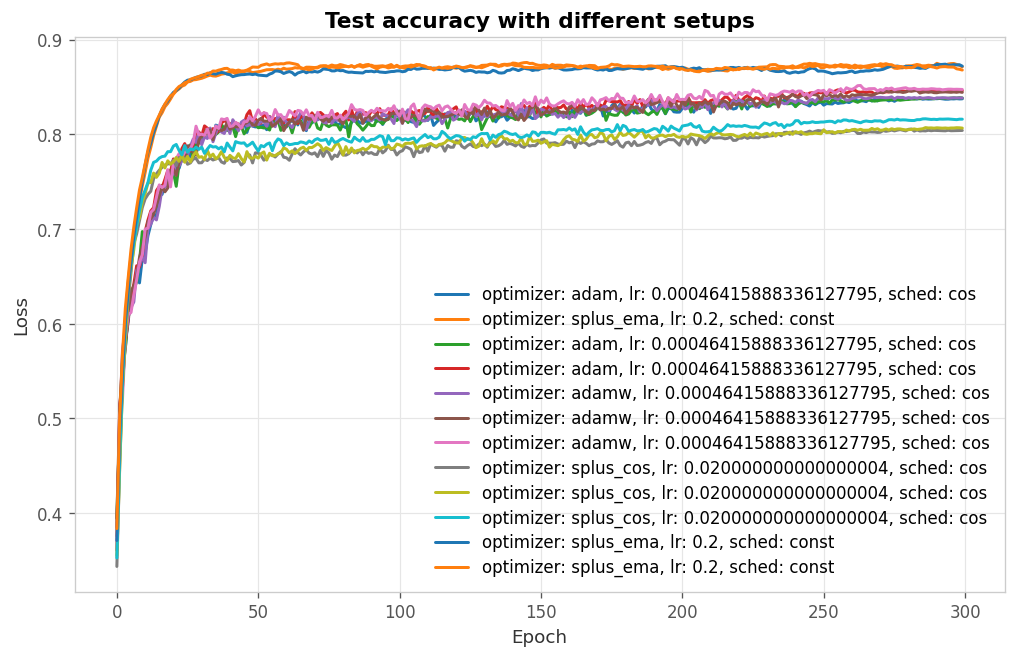

In [42]:
plt.figure(figsize=(10,6))
plt.title('Test accuracy with different setups')
plt.xlabel('Epoch')
plt.ylabel('Loss')
for file in files:
    with open(f"results/{file}", "r", encoding="utf-8") as f:
        data = json.load(f)
    cfg = data['cfg']
    train_loss = data['train_loss'][:300]
    test_loss = data['test_loss'][:300]
    test_acc = data['test_acc'][:300]
    time = data['time']
    plt.plot(np.arange(len(test_acc)), test_acc, label ='optimizer: '+cfg['name']+", lr: "+ str(cfg['lr'])+", sched: " +cfg['sched'])
    #plt.plot(np.arange(len(test_loss)), test_loss, label ='test_loss')
    #plt.title('optimizer: '+cfg['name']+", lr: "+ str(cfg['lr'])+", sched: " +cfg['sched'])
    
plt.grid(True)
plt.legend()

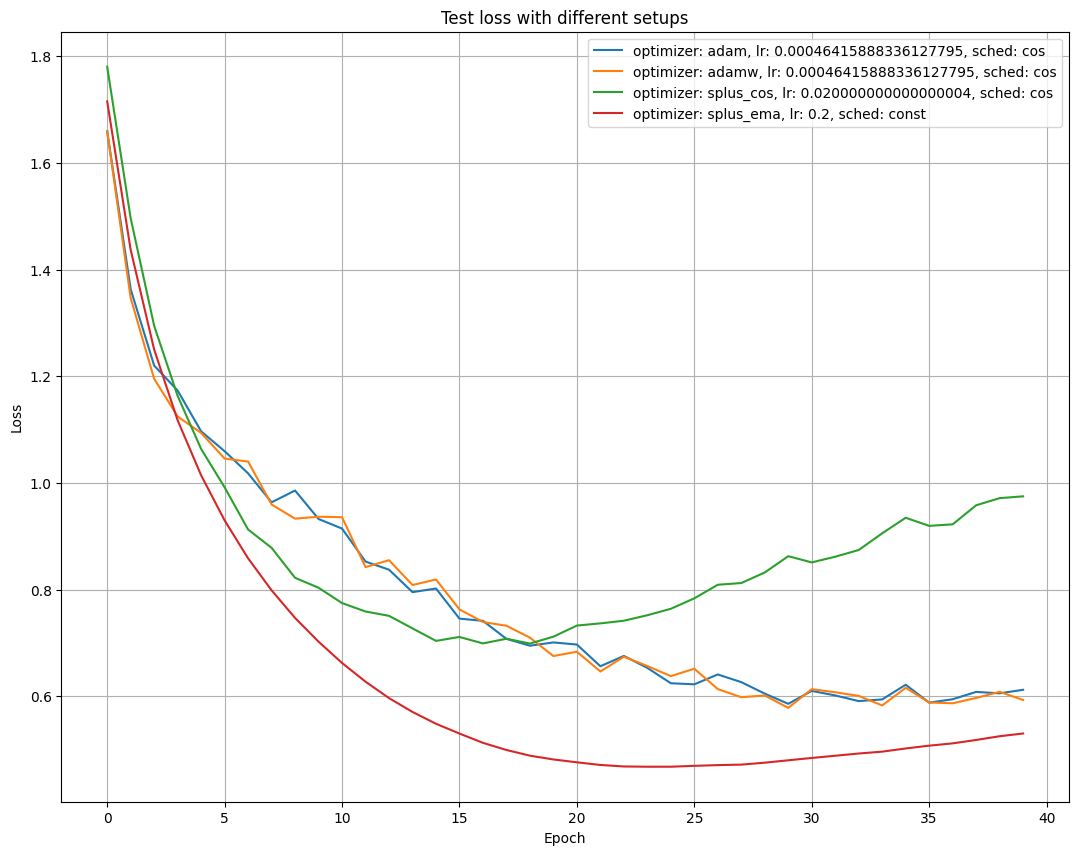

In [30]:
plt.figure(figsize=(13,10))
plt.title('Test loss with different setups')
plt.xlabel('Epoch')
plt.ylabel('Loss')
for file in files:
    with open(f"results/{file}", "r", encoding="utf-8") as f:
        data = json.load(f)
    cfg = data['cfg']
    train_loss = data['train_loss'][:40]
    test_loss = data['test_loss'][:40]
    test_acc = data['test_acc'][:40]
    time = data['time']
    plt.plot(np.arange(len(test_loss)), test_loss, label ='optimizer: '+cfg['name']+", lr: "+ str(cfg['lr'])+", sched: " +cfg['sched'])
    #plt.plot(np.arange(len(test_loss)), test_loss, label ='test_loss')
    #plt.title('optimizer: '+cfg['name']+", lr: "+ str(cfg['lr'])+", sched: " +cfg['sched'])
    
plt.grid(True)
plt.legend()

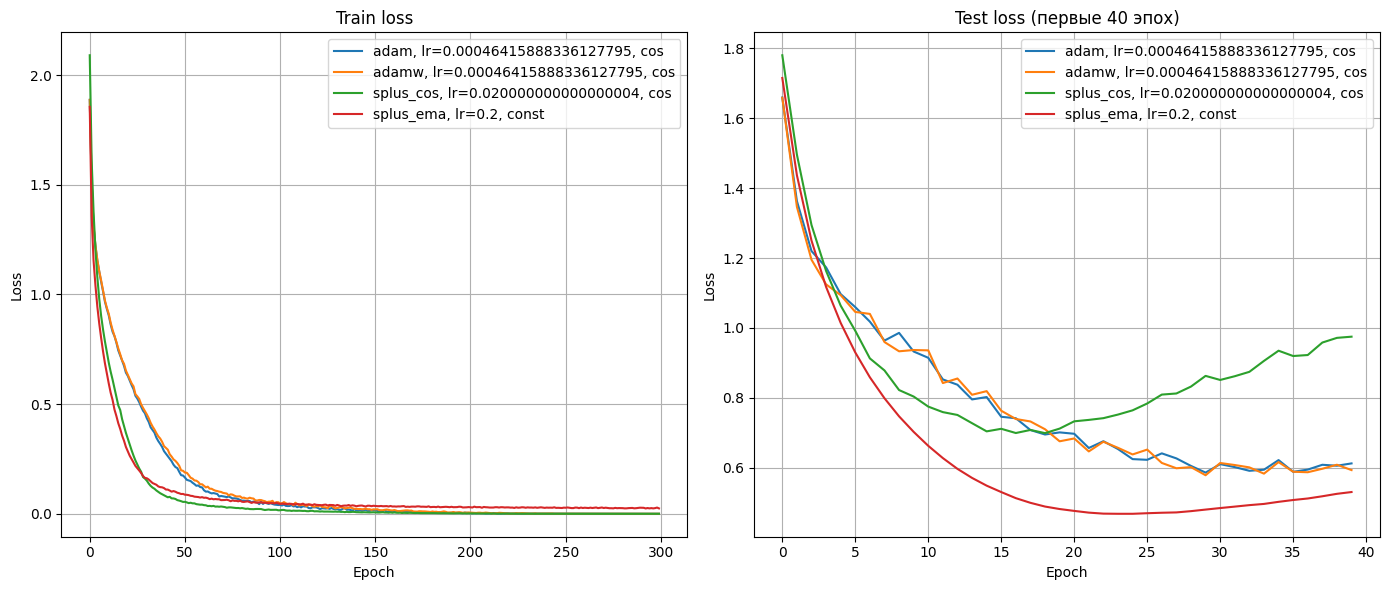

In [34]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

RESULTS = Path("results")
FILES = [
    "final_adam_0.0004642_s1.json",
    "final_adamw_0.0004642_s1.json",
    "final_splus_cos_0.02_s1.json",
    "final_splus_ema_0.2_s1.json",
]

def load(name):
    with open(RESULTS / name, encoding="utf-8") as f:
        return json.load(f)

def label(cfg):
    return f"{cfg['name']}, lr={cfg['lr']}, {cfg['sched']}"

def plot_metric(ax, metric, title, upto=None):
    for name in FILES:
        d = load(name)
        y = np.asarray(d[metric])
        if upto is not None:
            y = y[:upto]
        ax.plot(np.arange(len(y)), y, label=label(d["cfg"]))
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(True)
    ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_metric(axes[0], "train_loss", "Train loss")
plot_metric(axes[1], "test_loss", "Test loss (первые 40 эпох)", upto=40)
fig.tight_layout()
plt.show()

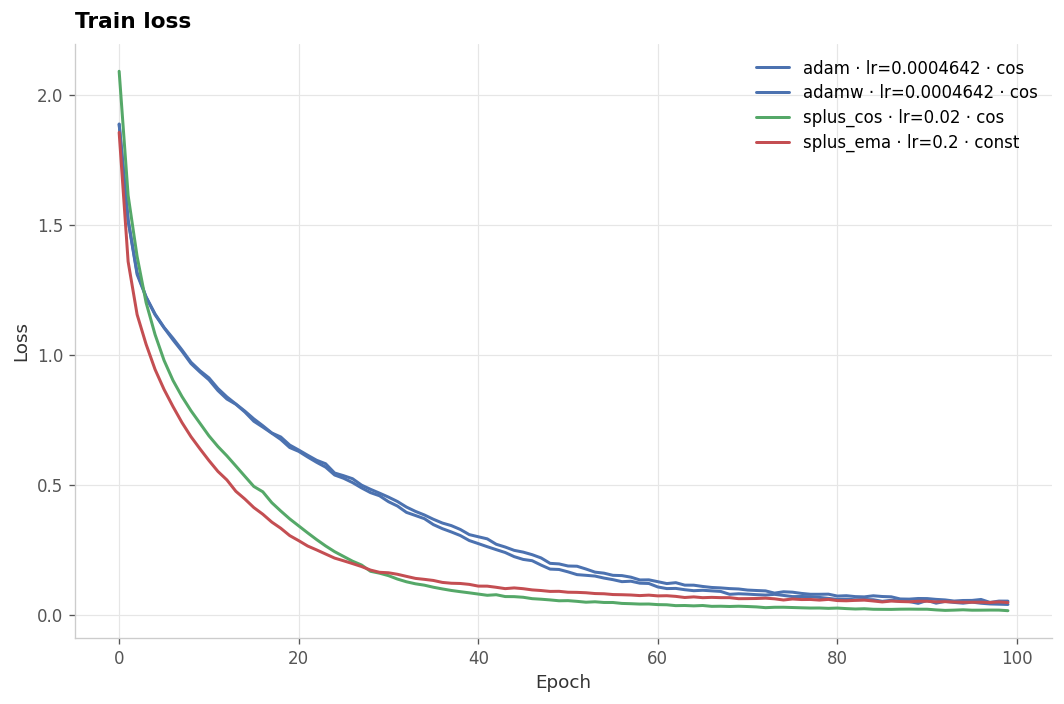

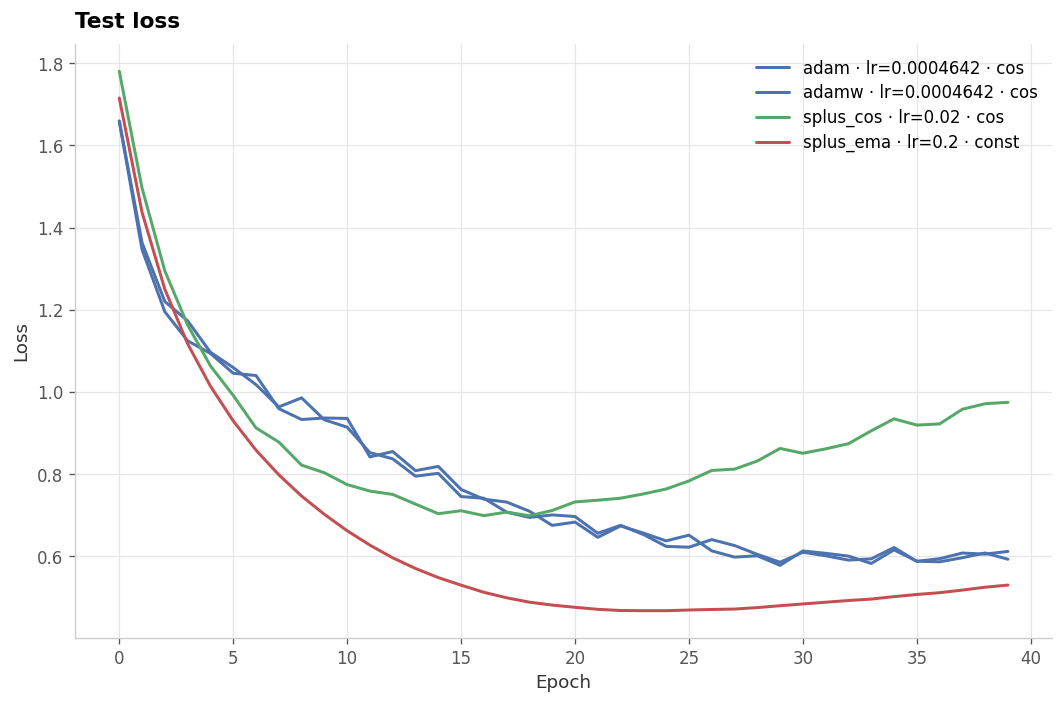

In [37]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np

# ---------- глобальный стиль ----------
mpl.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",

    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "semibold",
    "axes.labelsize": 11,
    "axes.labelcolor": "#333333",
    "axes.edgecolor": "#CCCCCC",
    "axes.linewidth": 0.8,

    "axes.grid": True,
    "grid.color": "#E6E6E6",
    "grid.linewidth": 0.7,
    "axes.axisbelow": True,

    "xtick.color": "#555555",
    "ytick.color": "#555555",
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,

    "legend.frameon": False,
    "legend.fontsize": 10,
    "legend.handlelength": 2.0,
    "legend.labelspacing": 0.4,

    "lines.linewidth": 1.8,
    "lines.solid_capstyle": "round",
})

# ---------- данные ----------
RESULTS = Path("results")
FILES = [
    "final_adam_0.0004642_s1.json",
    "final_adamw_0.0004642_s1.json",
    "final_splus_cos_0.02_s1.json",
    "final_splus_ema_0.2_s1.json",
]

PALETTE = {
    "adam":       "#4C72B0",
    "adamw":      "#DD8452",
    "splus_cos":  "#55A868",
    "splus_ema":  "#C44E52",
}

def color_for(cfg):
    for k, c in PALETTE.items():
        if k in cfg["name"]:
            return c
    return "#888888"

def fmt_lr(lr):
    # 7 знаков после запятой, хвостовые нули убираем
    return f"{lr:.7f}".rstrip("0").rstrip(".")

def short_label(cfg):
    return f"{cfg['name']} · lr={fmt_lr(cfg['lr'])} · {cfg['sched']}"

def load(name):
    with open(RESULTS / name, encoding="utf-8") as f:
        return json.load(f)

def make_figure(metric, title, upto=None, fname=None):
    fig, ax = plt.subplots(figsize=(9, 6))
    for name in FILES:
        d = load(name)
        y = np.asarray(d[metric])
        if upto is not None:
            y = y[:upto]
        ax.plot(
            np.arange(len(y)), y,
            color=color_for(d["cfg"]),
            label=short_label(d["cfg"]),
        )
    ax.set_title(title, loc="left", pad=10)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(loc="best")
    fig.tight_layout()
    if fname:
        fig.savefig(fname)
    return fig

# ---------- графики (отдельные фигуры) ----------
fig_train = make_figure("train_loss", "Train loss", upto=100, fname="train_loss.png")
fig_test  = make_figure("test_loss",  "Test loss", upto=40, fname="test_loss.png")

plt.show()